In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler

# Model
from sklearn.ensemble import RandomForestClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

# Class imbalance
from imblearn.over_sampling import SMOTE

# Save model
import joblib

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
#Load the Spambase Dataset
data = pd.read_csv("spambase.data", header=None)

print("Dataset shape:", data.shape)

data.head()

Dataset shape: (4601, 58)


,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,52,53,54,55,56,57
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


In [3]:
#Adding names to the Columns
column_names = [
    'word_freq_make',
    'word_freq_address',
    'word_freq_all',
    'word_freq_3d',
    'word_freq_our',
    'word_freq_over',
    'word_freq_remove',
    'word_freq_internet',
    'word_freq_order',
    'word_freq_mail',
    'word_freq_receive',
    'word_freq_will',
    'word_freq_people',
    'word_freq_report',
    'word_freq_addresses',
    'word_freq_free',
    'word_freq_business',
    'word_freq_email',
    'word_freq_you',
    'word_freq_credit',
    'word_freq_your',
    'word_freq_font',
    'word_freq_000',
    'word_freq_money',
    'word_freq_hp',
    'word_freq_hpl',
    'word_freq_george',
    'word_freq_650',
    'word_freq_lab',
    'word_freq_labs',
    'word_freq_telnet',
    'word_freq_857',
    'word_freq_data',
    'word_freq_415',
    'word_freq_85',
    'word_freq_technology',
    'word_freq_1999',
    'word_freq_parts',
    'word_freq_pm',
    'word_freq_direct',
    'word_freq_cs',
    'word_freq_meeting',
    'word_freq_original',
    'word_freq_project',
    'word_freq_re',
    'word_freq_edu',
    'word_freq_table',
    'word_freq_conference',

    'char_freq_semicolon',
    'char_freq_parenthesis',
    'char_freq_bracket',
    'char_freq_exclamation',
    'char_freq_dollar',
    'char_freq_hash',

    'capital_run_length_average',
    'capital_run_length_longest',
    'capital_run_length_total',

    'class'
]

print("Dataset columns:", data.shape[1])
print("Column names:", len(column_names))

data.columns = column_names

data.head()

Dataset columns: 58
Column names: 58


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_semicolon,char_freq_parenthesis,char_freq_bracket,char_freq_exclamation,char_freq_dollar,char_freq_hash,capital_run_length_average,capital_run_length_longest,capital_run_length_total,class
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


In [4]:
#Basic dataset inspection
print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])
print("Number of input features:", data.shape[1] - 1)

data.info()

Number of rows: 4601
Number of columns: 58
Number of input features: 57
<class 'pandas.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              4601 non-null   float64
 1   word_freq_address           4601 non-null   float64
 2   word_freq_all               4601 non-null   float64
 3   word_freq_3d                4601 non-null   float64
 4   word_freq_our               4601 non-null   float64
 5   word_freq_over              4601 non-null   float64
 6   word_freq_remove            4601 non-null   float64
 7   word_freq_internet          4601 non-null   float64
 8   word_freq_order             4601 non-null   float64
 9   word_freq_mail              4601 non-null   float64
 10  word_freq_receive           4601 non-null   float64
 11  word_freq_will              4601 non-null   float64
 12  word_freq_people            4

In [5]:
data.describe()

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_semicolon,char_freq_parenthesis,char_freq_bracket,char_freq_exclamation,char_freq_dollar,char_freq_hash,capital_run_length_average,capital_run_length_longest,capital_run_length_total,class
count,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,...,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000
mean,0.104553,0.213015,0.280656,0.065425,0.312223,0.095901,0.114208,0.105295,0.090067,0.239413,...,0.038575,0.139030,0.016976,0.269071,0.075811,0.044238,5.191515,52.172789,283.289285,0.394045
std,0.305358,1.290575,0.504143,1.395151,0.672513,0.273824,0.391441,0.401071,0.278616,0.644755,...,0.243471,0.270355,0.109394,0.815672,0.245882,0.429342,31.729449,194.891310,606.347851,0.488698
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.588000,6.000000,35.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.065000,0.000000,0.000000,0.000000,0.000000,2.276000,15.000000,95.000000,0.000000
75%,0.000000,0.000000,0.420000,0.000000,0.380000,0.000000,0.000000,0.000000,0.000000,0.160000,...,0.000000,0.188000,0.000000,0.315000,0.052000,0.000000,3.706000,43.000000,266.000000,1.000000
max,4.540000,14.280000,5.100000,42.810000,10.000000,5.880000,7.270000,11.110000,5.260000,18.180000,...,4.385000,9.752000,4.081000,32.478000,6.003000,19.829000,1102.500000,9989.000000,15841.000000,1.000000


In [6]:
#Finding Missing Values
missing_values = data.isnull().sum()

print("Missing values per column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values per column:
word_freq_make                0
word_freq_address             0
word_freq_all                 0
word_freq_3d                  0
word_freq_our                 0
word_freq_over                0
word_freq_remove              0
word_freq_internet            0
word_freq_order               0
word_freq_mail                0
word_freq_receive             0
word_freq_will                0
word_freq_people              0
word_freq_report              0
word_freq_addresses           0
word_freq_free                0
word_freq_business            0
word_freq_email               0
word_freq_you                 0
word_freq_credit              0
word_freq_your                0
word_freq_font                0
word_freq_000                 0
word_freq_money               0
word_freq_hp                  0
word_freq_hpl                 0
word_freq_george              0
word_freq_650                 0
word_freq_lab                 0
word_freq_labs                0
word_freq_tel

In [7]:
print(data.dtypes.value_counts())

float64    55
int64       3
Name: count, dtype: int64


In [8]:
categorical_columns = data.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Categorical input columns:", categorical_columns)

Categorical input columns: []


In [9]:
print("Therefore no encoding should be performed")

Therefore no encoding should be performed


In [10]:
#Check Duplicates
duplicate_count = data.duplicated().sum()

print("Duplicate rows before removal:", duplicate_count)

Duplicate rows before removal: 391


In [11]:
#Remove Duplicates
data = data.drop_duplicates().reset_index(drop=True)

print("Dataset shape after duplicate removal:", data.shape)
print("Duplicates remaining:", data.duplicated().sum())

Dataset shape after duplicate removal: (4210, 58)
Duplicates remaining: 0


In [12]:
#EDA Visualization 1: Class distribution
print(data['class'].value_counts())

print("\nPercentages:")
print(data['class'].value_counts(normalize=True) * 100)

class
0    2531
1    1679
Name: count, dtype: int64

Percentages:
class
0    60.118765
1    39.881235
Name: proportion, dtype: float64


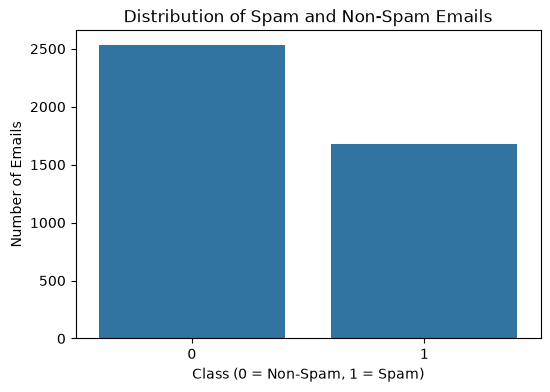

In [13]:
plt.figure(figsize=(6, 4))

sns.countplot(data=data, x='class')

plt.title("Distribution of Spam and Non-Spam Emails")
plt.xlabel("Class (0 = Non-Spam, 1 = Spam)")
plt.ylabel("Number of Emails")

plt.show()

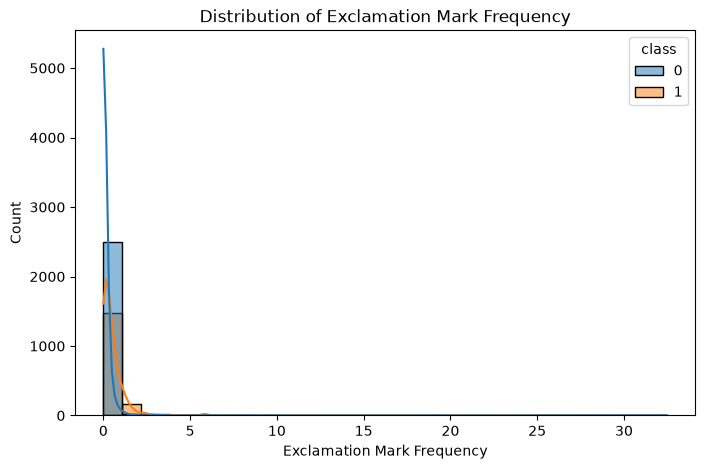

In [14]:
#EDA Visualization 2: Histogram
plt.figure(figsize=(8, 5))

sns.histplot(
    data=data,
    x='char_freq_exclamation',
    hue='class',
    bins=30,
    kde=True
)

plt.title("Distribution of Exclamation Mark Frequency")
plt.xlabel("Exclamation Mark Frequency")
plt.ylabel("Count")

plt.show()

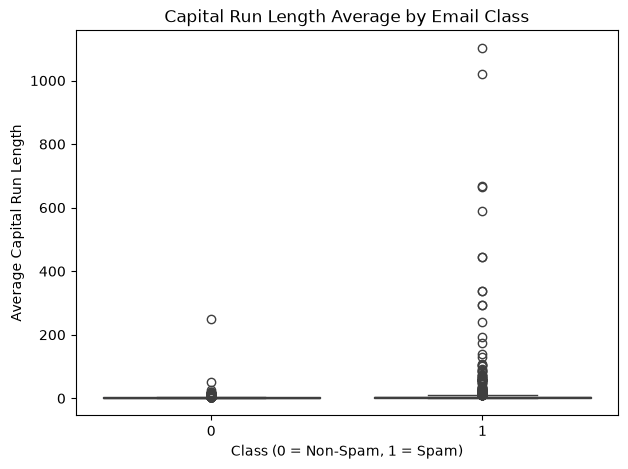

In [15]:
#EDA Visualization 3: Boxplot
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=data,
    x='class',
    y='capital_run_length_average'
)

plt.title("Capital Run Length Average by Email Class")
plt.xlabel("Class (0 = Non-Spam, 1 = Spam)")
plt.ylabel("Average Capital Run Length")

plt.show()

In [16]:
#EDA Visualization 4: Correlation
correlations = data.corr(numeric_only=True)['class'] \
                   .drop('class') \
                   .sort_values(key=abs, ascending=False)

print(correlations.head(15))

word_freq_your              0.394392
word_freq_remove            0.334456
char_freq_dollar            0.326603
word_freq_000               0.325716
word_freq_free              0.279261
word_freq_receive           0.272451
word_freq_hp               -0.270024
word_freq_business          0.260773
word_freq_you               0.256242
word_freq_hpl              -0.242411
char_freq_exclamation       0.233812
capital_run_length_total    0.231671
word_freq_our               0.230074
word_freq_order             0.221454
word_freq_over              0.212311
Name: class, dtype: float64


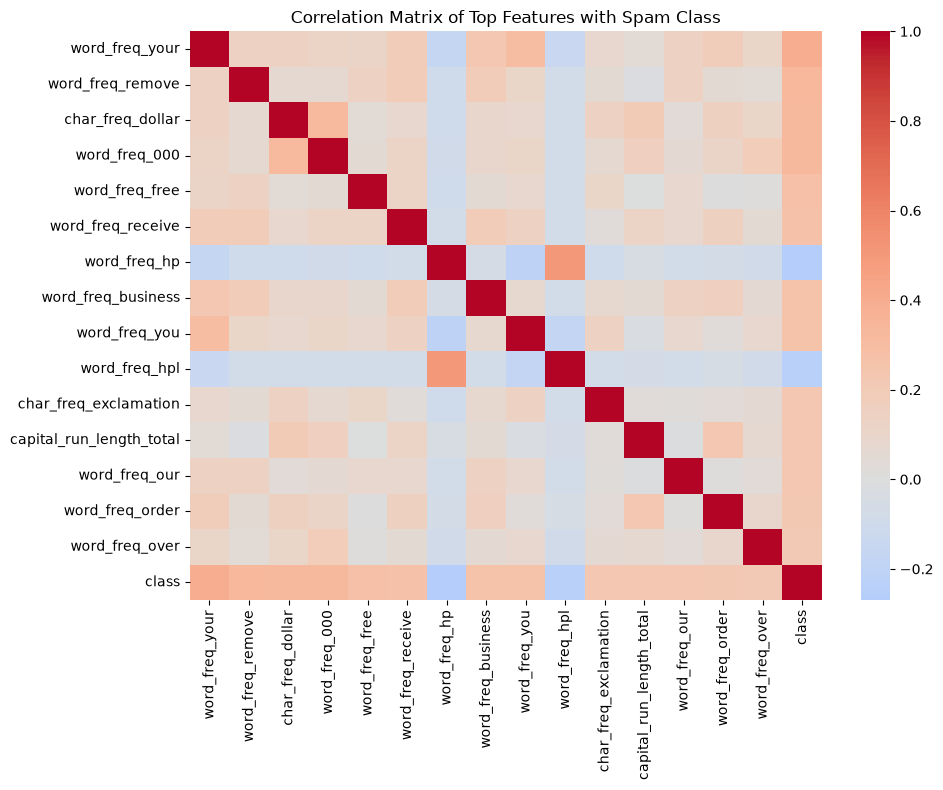

In [17]:
top_corr_features = correlations.head(15).index

plt.figure(figsize=(10, 8))

sns.heatmap(
    data[list(top_corr_features) + ['class']].corr(),
    cmap='coolwarm',
    center=0
)

plt.title("Correlation Matrix of Top Features with Spam Class")

plt.tight_layout()
plt.show()

In [18]:
#Outlier detection
X_temp = data.drop('class', axis=1)

Q1 = X_temp.quantile(0.25)
Q3 = X_temp.quantile(0.75)

IQR = Q3 - Q1

outlier_mask = (
    (X_temp < (Q1 - 1.5 * IQR)) |
    (X_temp > (Q3 + 1.5 * IQR))
)

outlier_counts = outlier_mask.sum().sort_values(ascending=False)

print("Top 15 features by potential outlier count:")
print(outlier_counts.head(15))

Top 15 features by potential outlier count:
word_freq_hp           1012
word_freq_make          982
word_freq_email         972
word_freq_over          933
word_freq_business      906
word_freq_free          830
word_freq_address       811
word_freq_1999          809
word_freq_people        806
word_freq_re            805
word_freq_hpl           789
word_freq_internet      767
word_freq_remove        762
char_freq_semicolon     750
word_freq_mail          748
dtype: int64


In [19]:
#Separate X and y
X = data.drop('class', axis=1)
y = data['class']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4210, 57)
y shape: (4210,)


In [20]:
#Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training set: (3368, 57)
Testing set: (842, 57)

Training distribution:
class
0    2025
1    1343
Name: count, dtype: int64

Testing distribution:
class
0    506
1    336
Name: count, dtype: int64


In [21]:
#Scaling/normalization demonstration
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling demonstration completed.")
print("Original training shape:", X_train.shape)
print("Scaled training shape:", X_train_scaled.shape)

Scaling demonstration completed.
Original training shape: (3368, 57)
Scaled training shape: (3368, 57)


In [22]:
#Apply SMOTE only to training data
print("Before SMOTE:")
print(y_train.value_counts())

Before SMOTE:
class
0    2025
1    1343
Name: count, dtype: int64


In [23]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())


After SMOTE:
class
1    2025
0    2025
Name: count, dtype: int64


In [24]:
#Baseline Random Forest
rf_baseline = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_baseline.fit(
    X_train_smote,
    y_train_smote
)

baseline_pred = rf_baseline.predict(X_test)
baseline_prob = rf_baseline.predict_proba(X_test)[:, 1]

In [25]:
baseline_results = {
    'Accuracy': accuracy_score(y_test, baseline_pred),
    'Precision': precision_score(y_test, baseline_pred),
    'Recall': recall_score(y_test, baseline_pred),
    'F1 Score': f1_score(y_test, baseline_pred),
    'ROC-AUC': roc_auc_score(y_test, baseline_prob)
}

print("Baseline Random Forest Results")

for metric, value in baseline_results.items():
    print(f"{metric}: {value:.4f}")

Baseline Random Forest Results
Accuracy: 0.9430
Precision: 0.9286
Recall: 0.9286
F1 Score: 0.9286
ROC-AUC: 0.9885


In [26]:
print(classification_report(y_test, baseline_pred))

              precision    recall  f1-score   support

           0       0.95      0.95      0.95       506
           1       0.93      0.93      0.93       336

    accuracy                           0.94       842
   macro avg       0.94      0.94      0.94       842
weighted avg       0.94      0.94      0.94       842



In [27]:
#Random Forest feature importance
feature_importance = pd.DataFrame({
    'Feature': X_train_smote.columns,
    'Importance': rf_baseline.feature_importances_
})

feature_importance = feature_importance.sort_values(
    'Importance',
    ascending=False
).reset_index(drop=True)

feature_importance.index += 1

feature_importance

,Feature,Importance
1,char_freq_exclamation,0.115922
2,char_freq_dollar,0.096024
3,word_freq_remove,0.088394
4,word_freq_free,0.076014
5,capital_run_length_average,0.063529
6,word_freq_hp,0.054165
7,word_freq_your,0.050720
8,capital_run_length_longest,0.045034
9,capital_run_length_total,0.044214
10,word_freq_our,0.030229


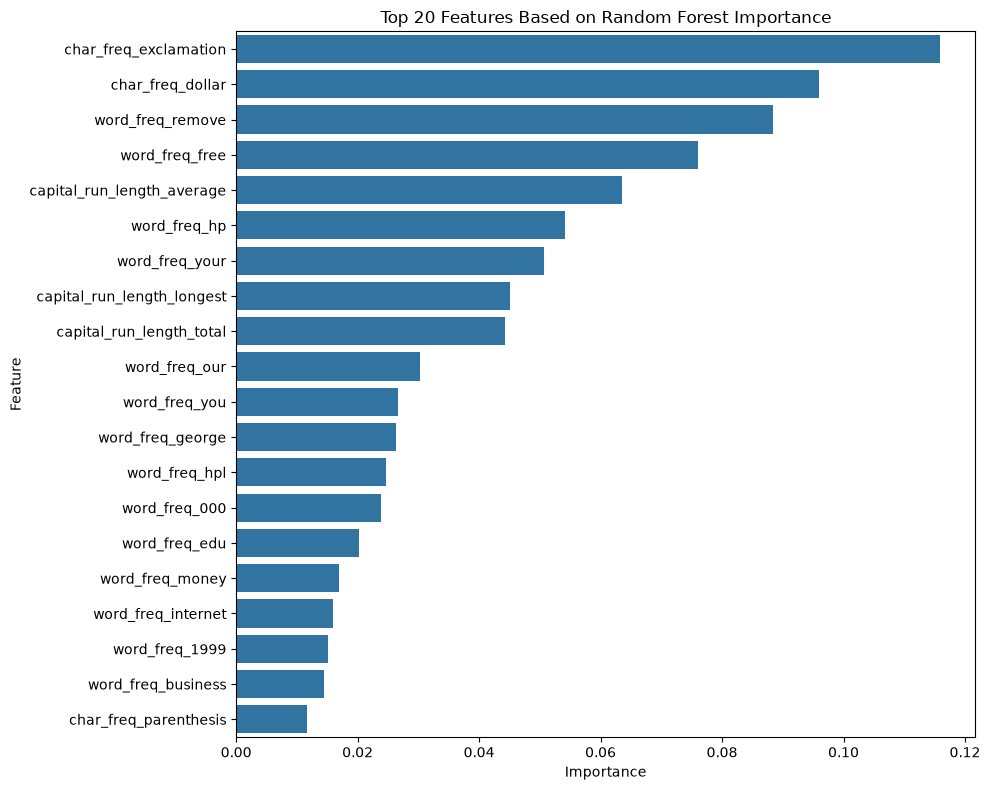

In [28]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=feature_importance.head(20),
    x='Importance',
    y='Feature'
)

plt.title("Top 20 Features Based on Random Forest Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [29]:
#use cross-validation on training data
feature_counts = [57, 30, 20, 15, 10, 7]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

feature_selection_results = []

for n in feature_counts:

    selected_features = (
        feature_importance
        .head(n)['Feature']
        .tolist()
    )

    X_selected = X_train_smote[selected_features]

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    f1_scores = cross_val_score(
        model,
        X_selected,
        y_train_smote,
        cv=cv,
        scoring='f1',
        n_jobs=-1
    )

    feature_selection_results.append({
        'Features': n,
        'Mean CV F1': f1_scores.mean(),
        'Std CV F1': f1_scores.std()
    })

feature_results_df = pd.DataFrame(feature_selection_results)

feature_results_df

,Features,Mean CV F1,Std CV F1
0,57,0.953418,0.007288
1,30,0.952223,0.005649
2,20,0.946529,0.006112
3,15,0.946007,0.006870
4,10,0.934109,0.009078
5,7,0.918216,0.004774


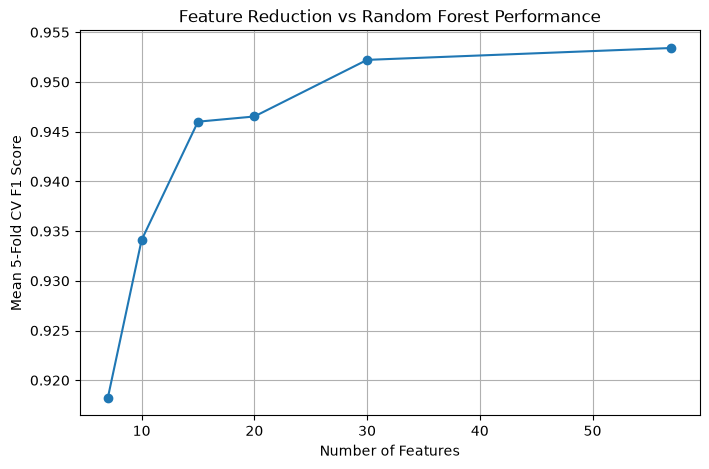

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(
    feature_results_df['Features'],
    feature_results_df['Mean CV F1'],
    marker='o'
)

plt.xlabel("Number of Features")
plt.ylabel("Mean 5-Fold CV F1 Score")
plt.title("Feature Reduction vs Random Forest Performance")
plt.grid(True)

plt.show()

In [ ]:
## 13. Final Feature Selection

Random Forest feature importance was used to rank the input features.

Models containing 57, 30, 20, 15, 10 and 7 features were evaluated using
5-fold stratified cross-validation.

The 15-feature model was selected because it substantially reduced
dimensionality while retaining performance close to the complete 57-feature
model. Further reduction to 10 and 7 features resulted in a more noticeable
decline in F1-score.

In [31]:
FINAL_FEATURE_COUNT = 15

selected_features = (
    feature_importance
    .head(FINAL_FEATURE_COUNT)['Feature']
    .tolist()
)

print("Selected 15 Features:")
print("---------------------")

for i, feature in enumerate(selected_features, start=1):
    print(f"{i}. {feature}")

Selected 15 Features:
---------------------
1. char_freq_exclamation
2. char_freq_dollar
3. word_freq_remove
4. word_freq_free
5. capital_run_length_average
6. word_freq_hp
7. word_freq_your
8. capital_run_length_longest
9. capital_run_length_total
10. word_freq_our
11. word_freq_you
12. word_freq_george
13. word_freq_hpl
14. word_freq_000
15. word_freq_edu


In [32]:
#Prepare the selected training data
X_train_final = X_train_smote[selected_features]
X_test_final = X_test[selected_features]

print("Training shape:", X_train_final.shape)
print("Testing shape:", X_test_final.shape)

Training shape: (4050, 15)
Testing shape: (842, 15)


In [ ]:
## 14. Random Forest Hyperparameter Tuning

GridSearchCV was used to systematically evaluate different combinations of
Random Forest hyperparameters.

The F1-score was selected as the optimization metric because the dataset
contains class imbalance and both false positives and false negatives are
important in spam classification.

Five-fold stratified cross-validation was used during tuning.

In [33]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2']
}

rf_tuning = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

grid_search = GridSearchCV(
    estimator=rf_tuning,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(
    X_train_final,
    y_train_smote
)

Fitting 5 folds for each of 72 candidates, totalling 360 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_exa

In [38]:
number_of_combinations = len(grid_search.cv_results_['params'])
total_fits = number_of_combinations * 5

print("Hyperparameter combinations:", number_of_combinations)
print("Cross-validation folds: 5")
print("Total model fits:", total_fits)

Hyperparameter combinations: 72
Cross-validation folds: 5
Total model fits: 360


In [39]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}

Best Cross-Validation F1 Score:
0.9470080558046702


In [40]:
best_rf = grid_search.best_estimator_

print(best_rf)

RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)


In [41]:
#Predict the untouched test data
final_pred = best_rf.predict(X_test_final)

final_prob = best_rf.predict_proba(X_test_final)[:, 1]

In [42]:
#Final evaluation
final_accuracy = accuracy_score(y_test, final_pred)
final_precision = precision_score(y_test, final_pred)
final_recall = recall_score(y_test, final_pred)
final_f1 = f1_score(y_test, final_pred)
final_auc = roc_auc_score(y_test, final_prob)

print("FINAL RANDOM FOREST RESULTS")
print("--------------------------------")

print(f"Accuracy : {final_accuracy:.4f}")
print(f"Precision: {final_precision:.4f}")
print(f"Recall   : {final_recall:.4f}")
print(f"F1 Score : {final_f1:.4f}")
print(f"ROC-AUC  : {final_auc:.4f}")

FINAL RANDOM FOREST RESULTS
--------------------------------
Accuracy : 0.9335
Precision: 0.9070
Recall   : 0.9286
F1 Score : 0.9176
ROC-AUC  : 0.9817


In [43]:
print(classification_report(
    y_test,
    final_pred,
    target_names=['Non-Spam', 'Spam']
))

              precision    recall  f1-score   support

    Non-Spam       0.95      0.94      0.94       506
        Spam       0.91      0.93      0.92       336

    accuracy                           0.93       842
   macro avg       0.93      0.93      0.93       842
weighted avg       0.93      0.93      0.93       842



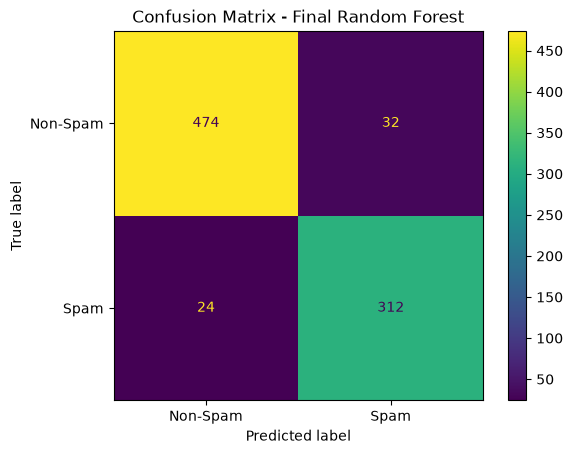

In [44]:
#Confusion Matrix
cm = confusion_matrix(y_test, final_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Non-Spam', 'Spam']
)

disp.plot()

plt.title("Confusion Matrix - Final Random Forest")
plt.show()

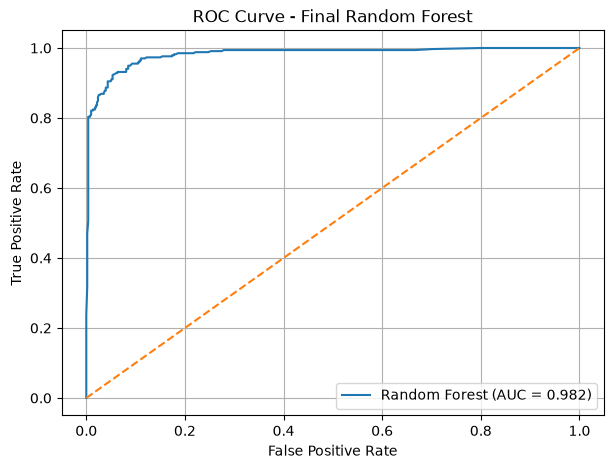

In [45]:
#ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    final_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'Random Forest (AUC = {final_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Final Random Forest")
plt.legend()
plt.grid(True)

plt.show()

In [46]:
#Comparing baseline vs final model
comparison_df = pd.DataFrame({
    'Model': [
        'Baseline Random Forest (57 Features)',
        'Final Tuned Random Forest (15 Features)'
    ],

    'Accuracy': [
        baseline_results['Accuracy'],
        final_accuracy
    ],

    'Precision': [
        baseline_results['Precision'],
        final_precision
    ],

    'Recall': [
        baseline_results['Recall'],
        final_recall
    ],

    'F1 Score': [
        baseline_results['F1 Score'],
        final_f1
    ],

    'ROC-AUC': [
        baseline_results['ROC-AUC'],
        final_auc
    ]
})

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Baseline Random Forest (57 Features),0.942993,0.928571,0.928571,0.928571,0.988498
1,Final Tuned Random Forest (15 Features),0.933492,0.906977,0.928571,0.917647,0.981678


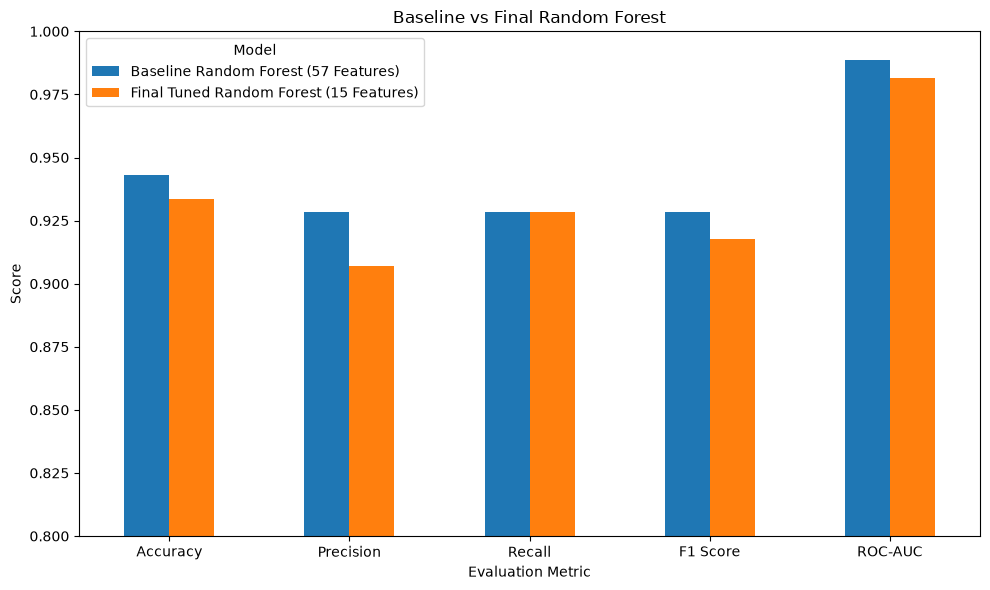

In [47]:
#Visual comparison
comparison_plot = comparison_df.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']
]

comparison_plot.T.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Baseline vs Final Random Forest")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0.8, 1.0)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()

plt.show()

In [ ]:
## 18. Dimensionality Reduction Summary

The selected model uses 15 of the original 57 features. The percentage of
features removed is calculated to quantify the dimensionality reduction achieved.

In [48]:
original_features = 57
final_features = 15

features_removed = original_features - final_features
reduction_percentage = (features_removed / original_features) * 100

print("Original number of features:", original_features)
print("Selected number of features:", final_features)
print("Features removed:", features_removed)
print(f"Feature reduction: {reduction_percentage:.2f}%")

Original number of features: 57
Selected number of features: 15
Features removed: 42
Feature reduction: 73.68%


In [49]:
#Quantify the performance trade-off
accuracy_change = final_accuracy - baseline_results['Accuracy']
precision_change = final_precision - baseline_results['Precision']
recall_change = final_recall - baseline_results['Recall']
f1_change = final_f1 - baseline_results['F1 Score']
auc_change = final_auc - baseline_results['ROC-AUC']

print("Performance Change: Final 15 Features - Baseline 57 Features")
print("------------------------------------------------------------")

print(f"Accuracy change : {accuracy_change:.4f}")
print(f"Precision change: {precision_change:.4f}")
print(f"Recall change   : {recall_change:.4f}")
print(f"F1 change       : {f1_change:.4f}")
print(f"ROC-AUC change  : {auc_change:.4f}")

Performance Change: Final 15 Features - Baseline 57 Features
------------------------------------------------------------
Accuracy change : -0.0095
Precision change: -0.0216
Recall change   : 0.0000
F1 change       : -0.0109
ROC-AUC change  : -0.0068


In [50]:
#Display the final 15 features again
selected_features_df = pd.DataFrame({
    'Rank': range(1, len(selected_features) + 1),
    'Selected Feature': selected_features
})

selected_features_df

,Rank,Selected Feature
0,1,char_freq_exclamation
1,2,char_freq_dollar
2,3,word_freq_remove
3,4,word_freq_free
4,5,capital_run_length_average
5,6,word_freq_hp
6,7,word_freq_your
7,8,capital_run_length_longest
8,9,capital_run_length_total
9,10,word_freq_our


In [ ]:
## 19. Model Comparison and Conclusion

The baseline Random Forest using all 57 features achieved the highest overall
predictive performance. However, the reduced Random Forest using 15 selected
features retained comparable classification performance while reducing the
number of input features by approximately 73.68%.

The 57-feature baseline achieved an accuracy of approximately 94.30%, whereas
the 15-feature tuned model achieved approximately 93.35%. The F1-score decreased
from approximately 92.86% to 91.76%. However, recall remained approximately
92.86% for both models.

Feature-reduction experiments using 57, 30, 20, 15, 10 and 7 features showed
that performance decreased more noticeably when the feature count was reduced
below 15. Therefore, 15 features were selected as a practical trade-off between
dimensionality reduction and predictive performance.

The results do not indicate that the 15-feature model is more accurate than
the 57-feature model. Instead, they demonstrate that substantial dimensionality
reduction can be achieved while retaining relatively similar classification
performance.

In [ ]:
## 20. Limitations and Future Improvements

### Limitations

1. Reducing the feature set from 57 to 15 resulted in a small reduction in
   accuracy, precision, F1-score and ROC-AUC.

2. Although SMOTE helps address class imbalance, synthetic samples may not
   perfectly represent real-world spam emails.

3. The Spambase dataset represents numerical features extracted from emails
   rather than modern raw email text.

4. Spam patterns continuously evolve, so a model trained using a fixed dataset
   may require retraining when applied to newer types of spam.

5. Random Forest feature importance can favour certain types of features and
   does not necessarily represent causal importance.

### Possible Improvements

1. Evaluate additional feature-selection techniques such as Mutual Information,
   Recursive Feature Elimination, or SHAP-based feature analysis.

2. Perform further hyperparameter optimization using RandomizedSearchCV or a
   larger GridSearchCV search space.

3. Evaluate the model using newer and more diverse email datasets.

4. Investigate cost-sensitive learning or class weighting as alternatives to
   SMOTE.

5. Develop a complete email-processing pipeline capable of extracting the
   required features from new raw email text.

In [51]:
joblib.dump(
    best_rf,
    "random_forest_spam_15_features.pkl"
)

print("Random Forest model saved successfully.")

Random Forest model saved successfully.


In [52]:
joblib.dump(
    selected_features,
    "random_forest_selected_features.pkl"
)

print("Selected feature list saved successfully.")

Selected feature list saved successfully.


In [53]:
joblib.dump(
    rf_baseline,
    "random_forest_baseline_57_features.pkl"
)

print("Baseline Random Forest saved successfully.")

Baseline Random Forest saved successfully.


In [54]:
comparison_df.to_csv(
    "random_forest_model_comparison.csv",
    index=False
)

feature_results_df.to_csv(
    "random_forest_feature_reduction_results.csv",
    index=False
)

feature_importance.to_csv(
    "random_forest_feature_importance.csv",
    index=False
)

selected_features_df.to_csv(
    "random_forest_selected_15_features.csv",
    index=False
)

print("All result tables saved successfully.")

All result tables saved successfully.


In [55]:
loaded_rf = joblib.load(
    "random_forest_spam_15_features.pkl"
)

loaded_features = joblib.load(
    "random_forest_selected_features.pkl"
)

print("Loaded model:")
print(loaded_rf)

print("\nNumber of loaded features:")
print(len(loaded_features))

print("\nLoaded features:")
for i, feature in enumerate(loaded_features, 1):
    print(f"{i}. {feature}")

Loaded model:
RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)

Number of loaded features:
15

Loaded features:
1. char_freq_exclamation
2. char_freq_dollar
3. word_freq_remove
4. word_freq_free
5. capital_run_length_average
6. word_freq_hp
7. word_freq_your
8. capital_run_length_longest
9. capital_run_length_total
10. word_freq_our
11. word_freq_you
12. word_freq_george
13. word_freq_hpl
14. word_freq_000
15. word_freq_edu


In [56]:
#Make a prediction using the saved model
sample_index = X_test.index[0]

sample = X_test.loc[[sample_index], loaded_features]

prediction = loaded_rf.predict(sample)[0]
probability = loaded_rf.predict_proba(sample)[0]

actual = y_test.loc[sample_index]

print("Actual class:", actual)
print("Predicted class:", prediction)

print(f"Probability of Non-Spam: {probability[0]:.4f}")
print(f"Probability of Spam: {probability[1]:.4f}")

if prediction == 1:
    print("\nPrediction: SPAM")
else:
    print("\nPrediction: NON-SPAM")

Actual class: 1
Predicted class: 1
Probability of Non-Spam: 0.4900
Probability of Spam: 0.5100

Prediction: SPAM


In [57]:
#Test several emails from the test set
sample_records = X_test.iloc[:10][loaded_features]

predictions = loaded_rf.predict(sample_records)
probabilities = loaded_rf.predict_proba(sample_records)[:, 1]

demo_results = pd.DataFrame({
    'Actual': y_test.iloc[:10].values,
    'Predicted': predictions,
    'Spam Probability': probabilities
})

demo_results['Actual Label'] = demo_results['Actual'].map({
    0: 'Non-Spam',
    1: 'Spam'
})

demo_results['Predicted Label'] = demo_results['Predicted'].map({
    0: 'Non-Spam',
    1: 'Spam'
})

demo_results[
    ['Actual Label', 'Predicted Label', 'Spam Probability']
]

,Actual Label,Predicted Label,Spam Probability
0,Spam,Spam,0.51000
1,Non-Spam,Non-Spam,0.00000
2,Spam,Spam,1.00000
3,Spam,Non-Spam,0.22000
4,Non-Spam,Spam,0.77000
5,Non-Spam,Non-Spam,0.00000
6,Spam,Non-Spam,0.35425
7,Spam,Spam,1.00000
8,Non-Spam,Non-Spam,0.00000
9,Spam,Spam,0.97000


In [ ]:
# Final Summary

This project developed a Random Forest classifier for spam email detection
using the UCI Spambase dataset.

The preprocessing stage included:

- Missing-value analysis
- Duplicate detection and removal
- Categorical-variable inspection
- Outlier analysis
- Scaling demonstration
- Class-distribution analysis
- SMOTE for class imbalance
- Exploratory Data Analysis

Random Forest feature importance was used for feature selection. Models using
57, 30, 20, 15, 10 and 7 features were evaluated using cross-validation.

The 15-feature subset was selected as a dimensionality-performance trade-off.
This reduced the original 57 features by approximately 73.68%.

Random Forest hyperparameters were subsequently optimized using GridSearchCV.
The final model was evaluated using accuracy, precision, recall, F1-score,
ROC-AUC, confusion matrix and ROC analysis.

The 57-feature baseline achieved slightly higher predictive performance than
the reduced model. However, the 15-feature model retained comparable
performance with substantially fewer input variables.

Finally, the trained Random Forest model and its selected feature list were
saved using Joblib for future prediction.

In [ ]:
## 21. Leakage-Safe Cross-Validation

To obtain a more rigorous validation estimate, SMOTE is applied inside each
cross-validation training fold rather than before cross-validation.

This prevents synthetic samples generated by SMOTE from influencing the
validation portion of a fold and reduces the risk of data leakage.

An imbalanced-learn Pipeline is used to combine SMOTE and Random Forest.

In [58]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [59]:
#Create 5-fold validation
cv_safe = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Leakage-safe 5-fold cross-validation created.")

Leakage-safe 5-fold cross-validation created.


In [60]:
X_train_15 = X_train[selected_features]

In [61]:
safe_pipeline = Pipeline([
    ('smote', SMOTE(random_state=42)),

    ('random_forest', RandomForestClassifier(
        **grid_search.best_params_,
        random_state=42,
        n_jobs=-1
    ))
])

In [62]:
safe_f1_scores = cross_val_score(
    safe_pipeline,
    X_train_15,
    y_train,
    cv=cv_safe,
    scoring='f1',
    n_jobs=-1
)

print("F1 scores for each fold:")
print(safe_f1_scores)

print("\nMean F1 Score:", safe_f1_scores.mean())
print("Standard Deviation:", safe_f1_scores.std())

F1 scores for each fold:
[0.91011236 0.94183865 0.90298507 0.89795918 0.93207547]

Mean F1 Score: 0.9169941477409467
Standard Deviation: 0.01703313581295549


In [ ]:
## 22. Leakage-Safe Feature Reduction Experiment

The feature subsets are re-evaluated using a pipeline in which SMOTE is
performed independently within each cross-validation training fold.

This provides a more reliable estimate of generalization performance.

In [63]:
safe_feature_results = []

feature_counts = [57, 30, 20, 15, 10, 7]

for n in feature_counts:

    features = (
        feature_importance
        .head(n)['Feature']
        .tolist()
    )

    X_subset = X_train[features]

    pipeline = Pipeline([
        ('smote', SMOTE(random_state=42)),

        ('random_forest', RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ])

    scores = cross_val_score(
        pipeline,
        X_subset,
        y_train,
        cv=cv_safe,
        scoring='f1',
        n_jobs=-1
    )

    safe_feature_results.append({
        'Features': n,
        'Mean CV F1': scores.mean(),
        'Std CV F1': scores.std()
    })

In [64]:
safe_feature_results_df = pd.DataFrame(
    safe_feature_results
)

safe_feature_results_df

,Features,Mean CV F1,Std CV F1
0,57,0.931732,0.016782
1,30,0.931466,0.016035
2,20,0.922873,0.017018
3,15,0.918383,0.013612
4,10,0.905011,0.009777
5,7,0.884940,0.012537


In [65]:
#Compare old vs safer validation
validation_comparison = feature_results_df.merge(
    safe_feature_results_df,
    on='Features',
    suffixes=('_Previous', '_Leakage_Safe')
)

validation_comparison

,Features,Mean CV F1_Previous,Std CV F1_Previous,Mean CV F1_Leakage_Safe,Std CV F1_Leakage_Safe
0,57,0.953418,0.007288,0.931732,0.016782
1,30,0.952223,0.005649,0.931466,0.016035
2,20,0.946529,0.006112,0.922873,0.017018
3,15,0.946007,0.006870,0.918383,0.013612
4,10,0.934109,0.009078,0.905011,0.009777
5,7,0.918216,0.004774,0.884940,0.012537


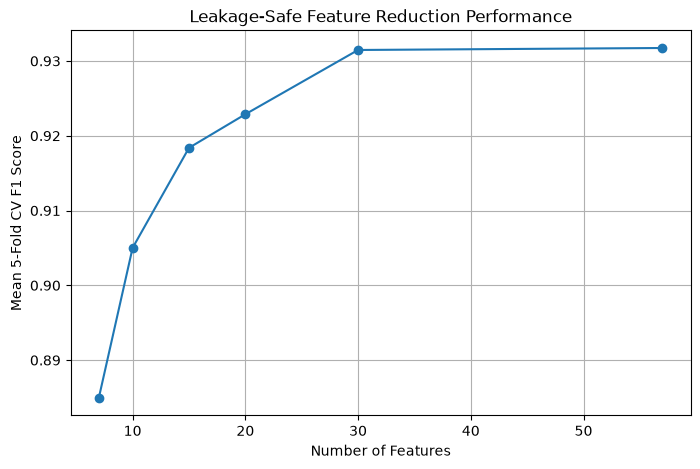

In [66]:
plt.figure(figsize=(8, 5))

plt.plot(
    safe_feature_results_df['Features'],
    safe_feature_results_df['Mean CV F1'],
    marker='o'
)

plt.xlabel("Number of Features")
plt.ylabel("Mean 5-Fold CV F1 Score")
plt.title("Leakage-Safe Feature Reduction Performance")
plt.grid(True)

plt.show()

In [67]:
safe_feature_results_df.to_csv(
    "random_forest_leakage_safe_validation.csv",
    index=False
)

print("Leakage-safe validation results saved.")

Leakage-safe validation results saved.


In [ ]:
### Leakage-Safe Validation Interpretation

When SMOTE was moved inside each cross-validation training fold, the estimated
F1-scores became lower than in the earlier experiment. This indicates that the
earlier procedure produced somewhat optimistic validation estimates.

The leakage-safe experiment achieved mean F1-scores of approximately 0.9317,
0.9315, 0.9229, 0.9184, 0.9050 and 0.8849 using 57, 30, 20, 15, 10 and 7
features respectively.

The 57- and 30-feature models produced the highest predictive performance.
However, the 15-feature subset was retained as an aggressive dimensionality
reduction trade-off. It removes approximately 73.68% of the original input
features while maintaining a mean cross-validation F1-score above 0.91.

The final 15-feature model also achieved an F1-score of approximately 0.9176
on the untouched test set, which is close to its leakage-safe cross-validation
performance. This provides additional evidence that its observed test
performance is reasonably consistent with its cross-validation performance.

The results demonstrate that reducing dimensionality involves a trade-off:
using more features maximizes predictive performance, while using 15 features
provides a substantially simpler representation with a relatively small
performance reduction. Further reduction to 10 or 7 features resulted in
progressively lower F1-scores.